# SIGMA-Vial · Control semafórico multiagente (SUMO + CrewAI)

Módulos en `src/`: `sigma_sim.py` (simulación), `sigma_crew.py` (agentes), `sigma_anim.py` (animación).

## 1. Instalación

In [ ]:
# Clona el repositorio (en Colab) y prepara rutas
import os, sys
REPO = "https://github.com/lexxvc/sigma-vial.git"
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone -q {REPO}
    %cd sigma-vial
elif os.path.basename(os.getcwd()) == "notebooks":
    %cd ..
!pip install -q -r requirements.txt
sys.path.insert(0, "src")

## 2. Archivos del proyecto
Red interna del campus (OSM recortado al polígono de la universidad), capa de simulación y capa multiagente.

In [ ]:
# Red del campus (OSM). Coloca tu archivo en data/mapa.osm
# o usa tu copia en Drive:
# from google.colab import drive; drive.mount('/content/drive')
# mapa = "/content/drive/MyDrive/tareas/map(1).osm"
mapa = "data/mapa.osm"

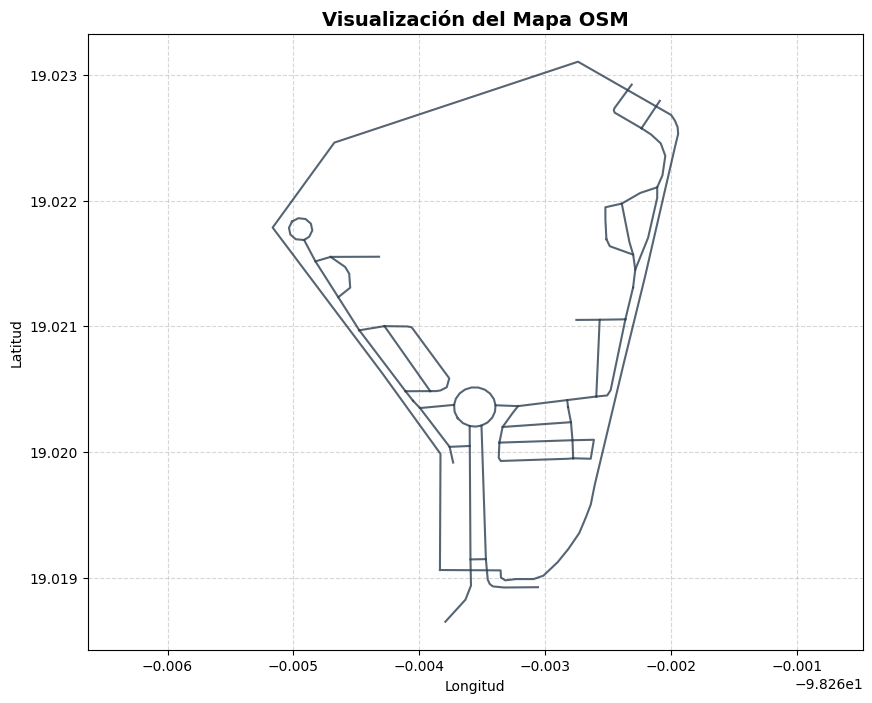

In [8]:
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

def graficar_osm(ruta_osm):
    try:
        tree = ET.parse(ruta_osm)
        root = tree.getroot()

        # Almacenar coordenadas de los nodos
        nodos = {}
        for node in root.findall('node'):
            node_id = node.get('id')
            lat = float(node.get('lat'))
            lon = float(node.get('lon'))
            nodos[node_id] = (lon, lat)

        plt.figure(figsize=(10, 8))

        # Dibujar los caminos (ways)
        for way in root.findall('way'):
            x, y = [], []
            for nd in way.findall('nd'):
                ref = nd.get('ref')
                if ref in nodos:
                    lon, lat = nodos[ref]
                    x.append(lon)
                    y.append(lat)
            if x and y:
                plt.plot(x, y, color='#2c3e50', linewidth=1.5, alpha=0.8)

        plt.title("Visualización del Mapa OSM", fontsize=14, fontweight='bold')
        plt.xlabel("Longitud")
        plt.ylabel("Latitud")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.axis("equal")
        plt.show()
    except Exception as e:
        print(f"Error al cargar o graficar el mapa: {e}")

graficar_osm(mapa)

## 3. Red, demanda y corrida de línea base (plan fijo)

In [19]:
import json, importlib, sigma_sim as sim
# Forzar la recarga del módulo corregido en memoria caché
importlib.reload(sim)

# Pasamos la variable 'mapa' explícitamente como argumento con la ruta correcta del Drive
net = sim.construir_red(osm=mapa)
rou = sim.generar_demanda(net)           # pulso de cambio de clase + ambulancia
base, foto = sim.simular(net, rou)       # plan fijo de netconvert (42 s / 42 s)
print("Métricas línea base:", json.dumps(base, indent=1))
print("\nFoto del estado entregada al Crew (resumen):")
for k, v in foto["intersecciones"].items():
    print(k, v["nombre"], "| verdes:", v["verdes_actuales_s"], "| peatones:", v["peatones_esperando"],
          "| sensores en falla:", [c for c, x in v["carriles"].items() if x is None])
print("Tramos:", foto["tramos_compartidos"]); print("Emergencia:", foto["emergencia"])

## 4. Modelo de lenguaje


In [20]:
import os
from crewai import LLM
try:
    from google.colab import userdata
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception as e:
    print("Sin Colab Secrets; usa la variable de entorno GEMINI_API_KEY.", e)
MODELO = "gemini/gemini-2.5-flash"
llm = LLM(model=MODELO, temperature=0.2)

## 5. Ejecución del Crew


In [21]:
import nest_asyncio
nest_asyncio.apply()

import sigma_crew as sc
import importlib
importlib.reload(sc)
sc.set_foto(foto)
crew = sc.crear_crew(llm, verbose=False)
resultado = await crew.kickoff_async(inputs={"hora": "09:00"})
plan_final = resultado.pydantic
print(plan_final.model_dump_json(indent=2))

{
  "aprobado": false,
  "planes": [
    {
      "interseccion": "I1",
      "verdes_s": [
        8,
        8
      ],
      "justificacion": "El plan inicial de [5, 8] para I1 fue corregido a [8, 8] debido a que los verdes estaban fuera del rango permitido [8, 60] segundos. La justificación original para el ajuste a [5, 8] era mitigar el spillback detectado en el tramo I1->I3 (ocupación del 74.7%), buscando aumentar la utilidad esperada y reducir el ciclo total de la intersección. Sin embargo, la regla de seguridad prevalece."
    },
    {
      "interseccion": "I2",
      "verdes_s": [
        9,
        9
      ],
      "justificacion": "Para mejorar la coordinación con las intersecciones I3 y I4, y mantener el régimen de 'ciclos cortos y alta frecuencia peatonal'. Aunque el plan [7, 7] ofrecía una utilidad ligeramente superior (26.97 vs 25.4), el plan [9, 9] establece un ciclo de 28 segundos, lo que facilita la coordinación con I3 (también con un ciclo de 28s) y I4 (con un ciclo 

## 6. Plan final consolidado

In [22]:
from IPython.display import Markdown, display
display(Markdown(plan_final.reporte_markdown))

plan = {p.interseccion: p.verdes_s for p in plan_final.planes}
val = json.loads(sc.validar_reglas.run(plan_json=json.dumps(plan)))
plan_aplicar = val["plan_corregido"]  # siempre se aplica la versión validada
print("Plan a aplicar:", plan_aplicar, "| violaciones:", val["violaciones"])

# Reporte de Plan de Tráfico Aprobado

**Estado General:** El plan ha sido **APROBADO CON CORRECCIONES**.

## Resumen Ejecutivo:
El plan coordinado inicial presentaba una violación de las reglas de seguridad en la intersección I1, donde la duración de una fase verde estaba fuera del rango permitido. Esta fase ha sido corregida automáticamente para cumplir con la normativa. Las demás intersecciones cumplen con las reglas de seguridad.

Se ha implementado una **prioridad de emergencia** en las intersecciones I3 e I4 para facilitar el paso de un vehículo de emergencia.

## Detalles por Intersección:

### Intersección I1:
- **Plan de Verdes (s):** [8, 8]
- **Justificación:** El plan inicial de [5, 8] para I1 fue corregido a [8, 8] debido a que los verdes estaban fuera del rango permitido [8, 60] segundos. La justificación original para el ajuste a [5, 8] era mitigar el spillback detectado en el tramo I1->I3 (ocupación del 74.7%), buscando aumentar la utilidad esperada y reducir el ciclo total de la intersección. Sin embargo, la regla de seguridad prevalece.

### Intersección I2:
- **Plan de Verdes (s):** [9, 9]
- **Justificación:** Para mejorar la coordinación con las intersecciones I3 y I4, y mantener el régimen de 'ciclos cortos y alta frecuencia peatonal'. Aunque el plan [7, 7] ofrecía una utilidad ligeramente superior (26.97 vs 25.4), el plan [9, 9] establece un ciclo de 28 segundos, lo que facilita la coordinación con I3 (también con un ciclo de 28s) y I4 (con un ciclo de 56s, el doble). La espera peatonal se mantiene en un nivel razonable (14s).

### Intersección I3:
- **Plan de Verdes (s):** [10, 8]
- **Justificación:** Para priorizar el paso del vehículo de emergencia hacia su destino. Se ha aumentado el verde de la fase que atiende el acceso del vehículo de emergencia (asumiendo que es la primera fase) de 8 a 10 segundos. Esta duración de verde, aunque ligeramente menor que otras opciones de máxima prioridad, permite un ciclo de 28 segundos, lo que es crucial para la coordinación con I2 y para mantener el principio de 'ciclos cortos' en la medida de lo posible, sin comprometer significativamente la prioridad de la emergencia. La utilidad esperada es de 11.61.

### Intersección I4:
- **Plan de Verdes (s):** [12, 8, 8, 8]
- **Justificación:** Para dar prioridad al acceso del vehículo de emergencia. Se ha aumentado significativamente el verde de la fase que atiende el acceso del vehículo de emergencia (asumiendo que es la primera fase) de 8 a 12 segundos. Esta extensión asegura un paso más rápido para la ambulancia. El ciclo resultante es de 56 segundos, lo que permite una coordinación efectiva al ser el doble del ciclo de I2 e I3. Si bien esto implica una mayor espera peatonal (28s) y una menor utilidad general (1.87), es una compensación necesaria para la prioridad de la emergencia, según lo indicado por la directriz "si es posible" para los ciclos cortos.

## Vetos o Correcciones Aplicadas:
- I1: verdes fuera de [8, 60] s → recortados a [8, 8]

## Prioridad de Emergencia:
Prioridad de paso para vehículo de emergencia en I3 e I4.

Plan a aplicar: {'I1': [8, 8], 'I2': [9, 9], 'I3': [10, 8], 'I4': [12, 8, 8, 8]} | violaciones: []


## 7. Evaluación: plan del Crew vs plan fijo (misma demanda y semilla)

,Plan fijo,SIGMA-Vial (Crew),Mejora %
vehiculos,301.0,301.0,0.0
espera_promedio_s,229.9,64.9,71.8
espera_p95_s,694.0,173.0,75.1
espera_max_continua_s,150.0,120.0,20.0
segundos_con_spillback,0.0,0.0,NaN
teleports_bloqueo,48.0,4.0,91.7
tiempo_ambulancia_s,750.0,149.0,80.1


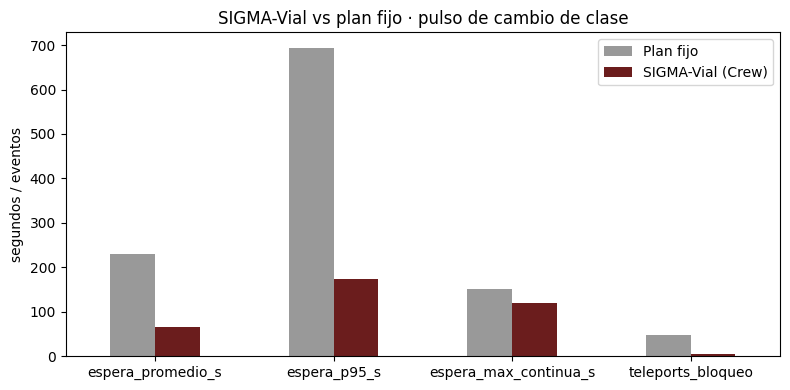

In [23]:
import pandas as pd, matplotlib.pyplot as plt
crew_m, _ = sim.simular(net, rou, plan=plan_aplicar)
tabla = pd.DataFrame({"Plan fijo": base, "SIGMA-Vial (Crew)": crew_m})
tabla["Mejora %"] = ((tabla["Plan fijo"] - tabla["SIGMA-Vial (Crew)"]) / tabla["Plan fijo"] * 100).round(1)
display(tabla)
met = ["espera_promedio_s", "espera_p95_s", "espera_max_continua_s", "teleports_bloqueo"]
ax = tabla.loc[met, ["Plan fijo", "SIGMA-Vial (Crew)"]].plot.bar(figsize=(8, 4), color=["#999", "#6b1d1d"], rot=0)
ax.set_title("SIGMA-Vial vs plan fijo · pulso de cambio de clase"); ax.set_ylabel("segundos / eventos")
plt.tight_layout(); plt.savefig("comparacion.png", dpi=150); plt.show()

## 8. Animación: plan fijo vs SIGMA-Vial
Minutos 7 a 13 del pulso (incluye la ambulancia a los 10 min). Se guarda `simulacion.gif`.

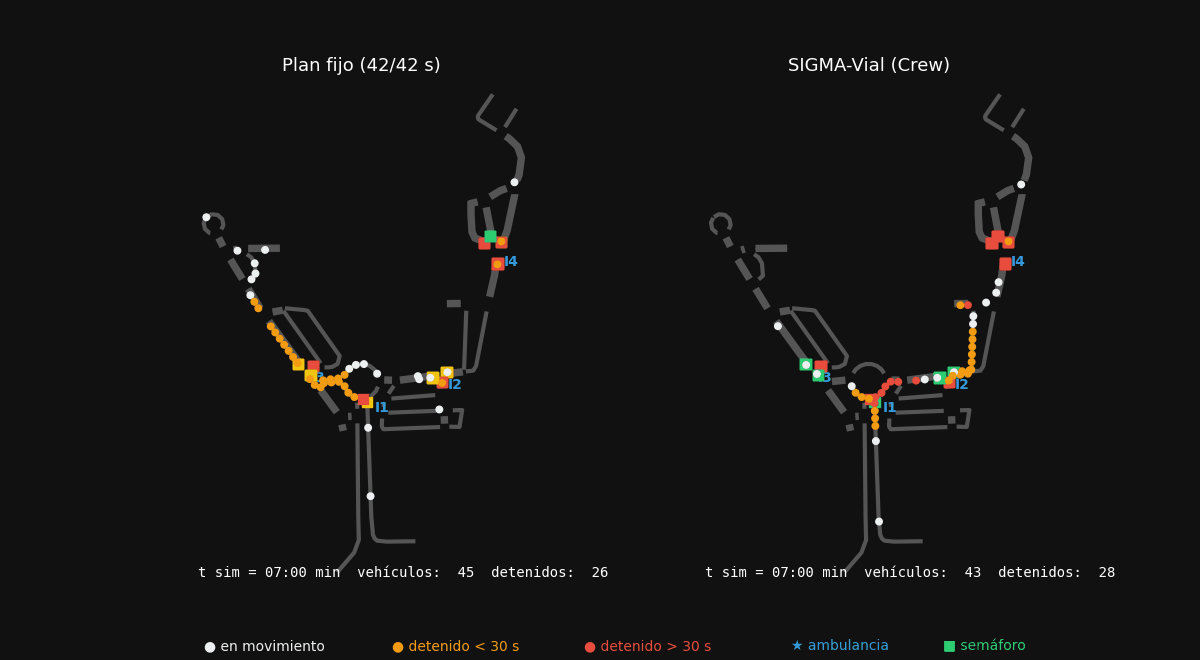

In [24]:
import sigma_anim as an
from IPython.display import Image as IImage
fb = an.grabar(net, rou)                      # plan fijo
fc = an.grabar(net, rou, plan=plan_aplicar)   # plan del Crew
an.animar(net, {"Plan fijo (42/42 s)": fb, "SIGMA-Vial (Crew)": fc}, "simulacion.gif")
IImage(filename="simulacion.gif")

## 9. Guardar evidencias para el PDF

In [25]:
os.makedirs("results", exist_ok=True)
json.dump({"entrada_foto": foto, "plan_final": plan_final.model_dump(), "metricas": tabla.to_dict()},
          open("results/sigma_resultado.json", "w"), ensure_ascii=False, indent=1)

## 10. Interfaz en tiempo real
Abre una ventana con el mapa en vivo: agrega autos o ambulancias por acceso y cambia el plan semafórico en caliente.

In [ ]:
sys.path.insert(0, "app")
import servidor
servidor.lanzar(puerto=5000, abrir=False, bloquear=False)
try:
    from google.colab import output
    output.serve_kernel_port_as_window(5000)   # Colab: abre la app en otra pestaña
except ImportError:
    print("Abre http://localhost:5000")